# Explore PDF parsing on local sample papers

This notebook reads PDFs from `notebooks/data/raw/pdf_parser_sample/`, parses text and tables with Docling, extracts embedded raster images with PyMuPDF, and writes one JSON result per PDF to `data/interim/pdf_parsing/sample/`.

No `.env`, Google Cloud, Drive credentials, or GenAI access is needed. The first Docling run may download its parser models. OCR is off; these six PDFs have text layers.

**Alternatives to try later:** `pymupdf4llm` for text/Markdown; `pdfplumber` or Camelot for tables; GROBID for scholarly article structure; Marker or MinerU for broader layout-aware parsing. Compare one alternative on the same local PDFs before adding more.

Select the repository `.venv` notebook kernel. If needed, install the notebook dependencies from the repository root with `uv sync --group notebook`.


## 1. Find and validate the local PDFs


In [1]:
import io
import json
from pathlib import Path

import pymupdf
from docling.datamodel.base_models import DocumentStream, InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, PdfFormatOption
from docling_core.types.doc import TableItem
from IPython.display import Image, Markdown, display

from steel_slag_slm.config import PROJECT_ROOT

INPUT_DIR = PROJECT_ROOT / "notebooks" / "data" / "raw" / "pdf_parser_sample"
OUTPUT_DIR = PROJECT_ROOT / "data" / "interim" / "pdf_parsing" / "sample"
PDF_PATHS = sorted(INPUT_DIR.glob("*.pdf"))

if not INPUT_DIR.is_dir():
    raise FileNotFoundError(f"Sample PDF folder does not exist: {INPUT_DIR}")
if not PDF_PATHS:
    raise FileNotFoundError(f"No .pdf files found in {INPUT_DIR}")

for pdf_path in PDF_PATHS:
    with pymupdf.open(pdf_path) as pdf:
        if pdf.page_count == 0:
            raise ValueError(f"PDF has no pages: {pdf_path.name}")
        word_count = sum(len(page.get_text("words")) for page in pdf)
        print(f"{pdf_path.name}: {pdf.page_count} pages, {word_count:,} text-layer words")
        if word_count == 0:
            print("  Warning: no text layer detected; OCR may be needed for this PDF.")

print(f"\nFound {len(PDF_PATHS)} PDF(s).")

/home/kanewyp/Projects/Steel-Slag-SLM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W2068066265.pdf: 11 pages, 6,001 text-layer words
W2103905583.pdf: 7 pages, 4,645 text-layer words
W2170257698.pdf: 14 pages, 7,860 text-layer words
W2284653934.pdf: 6 pages, 4,036 text-layer words
W2985324803.pdf: 10 pages, 4,638 text-layer words
W3003793339.pdf: 12 pages, 5,298 text-layer words

Found 6 PDF(s).


## 2. Parse text and tables with Docling

The `markdown` field is the full parsed output. `tables` stores tables separately for convenient review. Model initialization happens once; the converter is reused for each PDF.


In [2]:
pipeline_options = PdfPipelineOptions(
    do_ocr=False,
    do_table_structure=True,
)
converter = DocumentConverter(
    format_options={InputFormat.PDF: PdfFormatOption(pipeline_options=pipeline_options)}
)


def parse_with_docling(pdf_path: Path) -> tuple[str, list[str]]:
    """Return full Markdown and individually exported tables for one PDF."""
    document = converter.convert(
        DocumentStream(name=pdf_path.name, stream=io.BytesIO(pdf_path.read_bytes()))
    ).document
    tables = [
        item.export_to_markdown(document)
        for item, _ in document.iterate_items()
        if isinstance(item, TableItem)
    ]
    return document.export_to_markdown(), tables


docling_results = {}
for pdf_path in PDF_PATHS:
    markdown, tables = parse_with_docling(pdf_path)
    docling_results[pdf_path.name] = {"markdown": markdown, "tables": tables}
    print(f"{pdf_path.name}: parsed {len(tables)} table(s)")

Loading weights: 100%|██████████| 770/770 [00:00<00:00, 1838.60it/s]


W2068066265.pdf: parsed 2 table(s)


Skipping page separator extraction on page 3: 6552 separator candidates exceed the limit of 5000. Such dense vector geometry cannot yield trustworthy page separators; reading order falls back to the pre-separator behavior.


W2103905583.pdf: parsed 1 table(s)
2026-10-17 18:02:36,312 MatchingPostProcessor WARNING  1 of 352 pdf cells matched neither a row nor a column band of the 17x21 grid and were dropped from the table
W2170257698.pdf: parsed 6 table(s)
W2284653934.pdf: parsed 2 table(s)
W2985324803.pdf: parsed 6 table(s)
W3003793339.pdf: parsed 4 table(s)


## 3. Extract embedded images with PyMuPDF

PyMuPDF returns embedded image resources, not semantic figures. One journal logo may be one resource, and one diagram may be split across several resources. The saved records include each resource's source page and bounding box so you can inspect and classify them.

For example, `W2068066265.pdf` has 8 embedded resources but 2 semantic diagrams: 3 resources are page-1 journal branding, while the other 5 are tiled pieces of the two diagrams on page 4. Use the gallery and page overlay below to confirm this visually; do not treat the raw resource count as a figure-accuracy score.


In [3]:
def extract_embedded_images(pdf_path: Path, image_dir: Path) -> list[dict[str, object]]:
    """Save unique embedded raster images and return their file details."""
    image_dir.mkdir(parents=True, exist_ok=True)
    images_by_xref = {}
    with pymupdf.open(pdf_path) as pdf:
        for page in pdf:
            for image_info in page.get_images(full=True):
                xref = image_info[0]
                image_record = images_by_xref.get(xref)
                if image_record is None:
                    image = pdf.extract_image(xref)
                    filename = f"image_{len(images_by_xref) + 1:03d}.{image['ext']}"
                    (image_dir / filename).write_bytes(image["image"])
                    image_record = {
                        "xref": xref,
                        "path": filename,
                        "width": image["width"],
                        "height": image["height"],
                        "placements": [],
                    }
                    images_by_xref[xref] = image_record
                for rect in page.get_image_rects(xref):
                    placement = {
                        "page": page.number + 1,
                        "bbox": [round(float(value), 1) for value in rect],
                    }
                    if placement not in image_record["placements"]:
                        image_record["placements"].append(placement)
    return list(images_by_xref.values())


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
results = {}
for pdf_path in PDF_PATHS:
    paper_dir = OUTPUT_DIR / pdf_path.stem
    image_records = extract_embedded_images(pdf_path, paper_dir / "images")
    with pymupdf.open(pdf_path) as pdf:
        page_count = pdf.page_count
    results[pdf_path.name] = {
        "source_pdf": pdf_path.name,
        "page_count": page_count,
        "parsers": {"text_and_tables": "Docling", "embedded_images": "PyMuPDF"},
        "docling": docling_results[pdf_path.name],
        "pymupdf": {"embedded_images": image_records},
    }
    json_path = paper_dir / "parsed.json"
    json_path.write_text(
        json.dumps(results[pdf_path.name], ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    print(
        f"Saved {json_path.relative_to(PROJECT_ROOT)} ({len(image_records)} embedded image resources)"
    )

print(f"\nParsed {len(results)} PDF(s). Results: {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Saved data/interim/pdf_parsing/sample/W2068066265/parsed.json (8 embedded image resources)
Saved data/interim/pdf_parsing/sample/W2103905583/parsed.json (0 embedded image resources)
Saved data/interim/pdf_parsing/sample/W2170257698/parsed.json (436 embedded image resources)
Saved data/interim/pdf_parsing/sample/W2284653934/parsed.json (43 embedded image resources)
Saved data/interim/pdf_parsing/sample/W2985324803/parsed.json (15 embedded image resources)
Saved data/interim/pdf_parsing/sample/W3003793339/parsed.json (316 embedded image resources)

Parsed 6 PDF(s). Results: data/interim/pdf_parsing/sample


## 4. Inspect parser output and original pages

The cell below shows a short text/table preview and a contact sheet for one PDF. The full parsed Markdown, tables, and image metadata are in each paper's `parsed.json`. To inspect a different PDF's extracted images, change `IMAGE_REVIEW_PDF`. Use `show_page` to view the original page with extracted-image boxes outlined.



W2068066265.pdf: 11 pages
Docling tables: 2 | PyMuPDF embedded image resources: 8


<!-- image -->

Available online at www.sciencedirect.com Available online at www.sciencedirect.com

Procedia Environmental Sciences 16 ( 2012 ) 791 - 801

<!-- image -->

The 7 th International Conference on Waste Management and Technology

## An overview of utilization of steel slag

Huang Yi�, Guoping Xu, Huigao Cheng, Junshi Wang, Yinfeng Wan, Hui Chen

Sinosteel Wuhan Safety &amp; Environmental Protection Research Institute, Wuhan 430081, PR China

## Abstract

The current utilization rate of steel slag is only 22% in china, far behind the developed countries. At present, the amount of slag deposited in storage yard adds up to 30Mt, leading to the occupation of farm land and serious pollution to the environment. Improving the slag utilization is an important way to resolve these problems. The physical and chemical characteristics of steel slag were analyzed and then the research progress of steel slag utilization at home and abroad as recycled raw material in steel enterprise interior, aggregate of road and hydraulic construction, cement additive and concrete admixture, materials for waste water or gas treatment, construction materials and fertilizer in agriculture production 

… *preview; see parsed.json for full text*

**Table 1**

Table 1. Chemical composition of steel slag

| Oxides/%   | CaO   | SiO2   | Al 2O3   | Fe2O3   | FeO   | MgO   | MnO   | P2O5   |
|------------|-------|--------|----------|---------|-------|-------|-------|--------|
| BOFS       | 45-60 | 10-15  | 1-5      | 3-9     | 7-20  | 3-13  | 2-6   | 1-4    |
| EAFS       | 30-50 | 11-20  | 10-18    | 5-6     | 8-22  | 8-13  | 5-10  | 2-5    |

**Table 2**

Table 2. Characteristics and applications of steel slag

| Characteristics                              | Applications                                   |
|----------------------------------------------|------------------------------------------------|
| Hard, wear-resistant, adhesive, rough        | Aggregates for road and hydraulic construction |
| Porous, alkaline                             | Waste water treatment                          |
| FeOx, Fe components                          | Iron reclamation                               |
| CaO,MgO,FeO,MgO,MnO componets                | Fluxing agent                                  |
| Cementitious components (C3S, C2S and C4AF ) | Cement and concrete production                 |
| CaO, MgO components                          | CO2 capture and flue gas desulfurization       |
| FeO, CaO, SiO2 components                    | Raw material for cement clinker                |
| Fertilizer components (CaO, SiO2, MgO, FeO)  | Fertilizer and soil improvement                |


W2103905583.pdf: 7 pages
Docling tables: 1 | PyMuPDF embedded image resources: 0


...

(4 more table(s) in parsed.json)

W3003793339.pdf: 12 pages
Docling tables: 4 | PyMuPDF embedded image resources: 316


<!-- image -->

Article

## Microwave Absorption Ability of Steel Slag and Road Performance of Asphalt Mixtures Incorporating Steel Slag

Baowen Lou 1 , Zhuangzhuang Liu 2,3 , Aimin Sha 1,2,3, *, Meng Jia 2 and Yupeng Li 2

- 1 School of Material Science and Engineering, Chang'an University, Xi'an 710064, China; loubaowen@chd.edu.cn
- 2 School of Highway, Chang'an University, Xi'an 710064, China; zzliu@chd.edu.cn (Z.L.); mengjia@chd.edu.cn (M.J.); liyupeng@chd.edu.cn (Y.L.)
- 3 Key Laboratory for Special Area Highway Engineering of Ministry of Education, Chang'an University, Xi'an 710064, China
* Correspondence: ams@chd.edu.cn

Received: 25 December 2019; Accepted: 29 January 2020; Published: 2 February 2020

<!-- image -->

Abstract: Excessive usage of non-renewable natural resources and massive construction wastes put pressure on the environment. Steel slags, the main waste material from the metal industry, are normally added in asphalt concrete to replace traditional aggregate. In addition, as a typical microwave absorber, steel slag has the potential to transfer microwave energy into heat, thus increasing the limited self-healing ability of asphalt mixture. This paper aims to i

… *preview; see parsed.json for full text*

**Table 1**

Table 1. Particle size distribution of aggregates.

|   Sieve Size (mm) |   Passing Rate (%) |
|-------------------|--------------------|
|              13.2 |                 95 |
|               9.5 |                 76 |
|              4.75 |                 53 |
|              2.36 |                 37 |
|              1.18 |                 27 |
|               0.6 |                 19 |
|               0.3 |                 13 |
|              0.15 |                 10 |
|             0.075 |                  5 |

**Table 2**

Table 2. Basic characteristics of aggregates used.

| Property             | Size (mm)   | Relative Bulk Specific Gravity (g/mm 3 )   | Los Angeles Abrasion Value (%)   | Water Absorption (%)   |
|----------------------|-------------|--------------------------------------------|----------------------------------|------------------------|
| Limestone Steel slag | 4.75-9.5    | 2.782 3.67                                 | 24.8 15.4                        | 0.61 1.01              |

(2 more table(s) in parsed.json)
xref 95: 1887x149 px; placements=[{'page': 1, 'bbox': [159.4, 61.5, 329.3, 74.8]}]


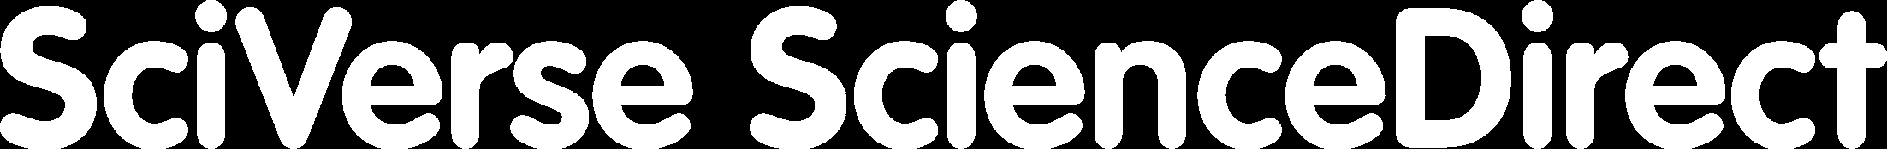

xref 97: 1236x672 px; placements=[{'page': 1, 'bbox': [400.5, 45.4, 511.8, 105.8]}]


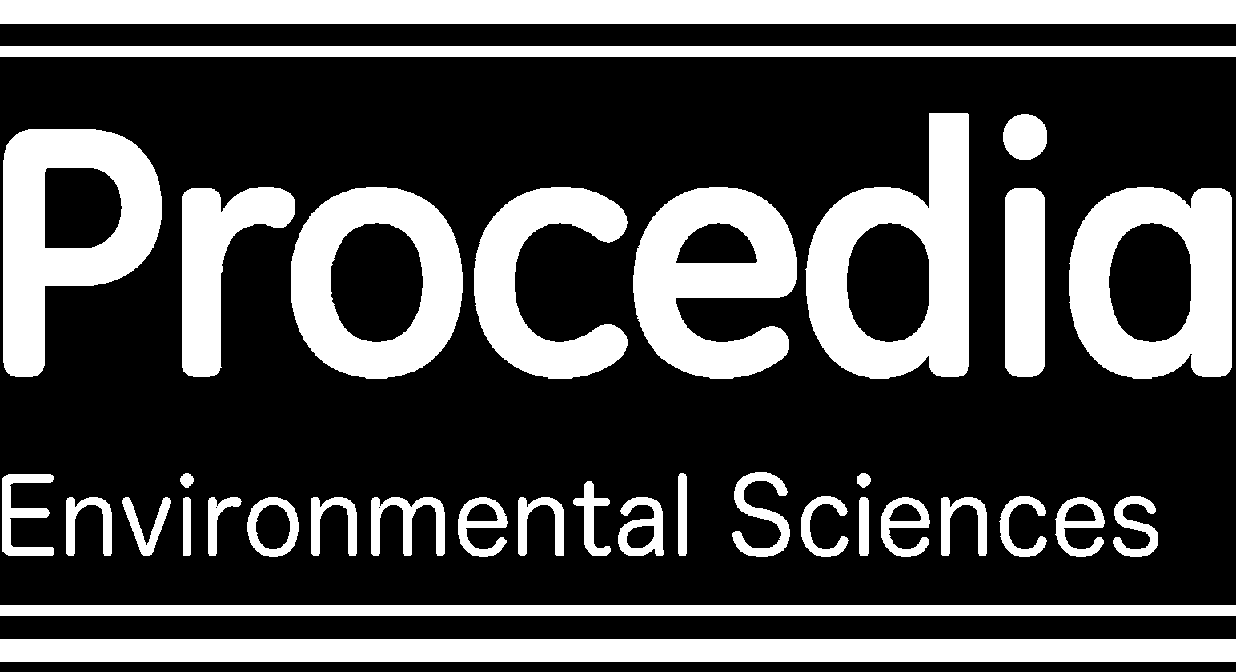

xref 99: 598x662 px; placements=[{'page': 1, 'bbox': [33.7, 45.3, 87.5, 104.9]}]


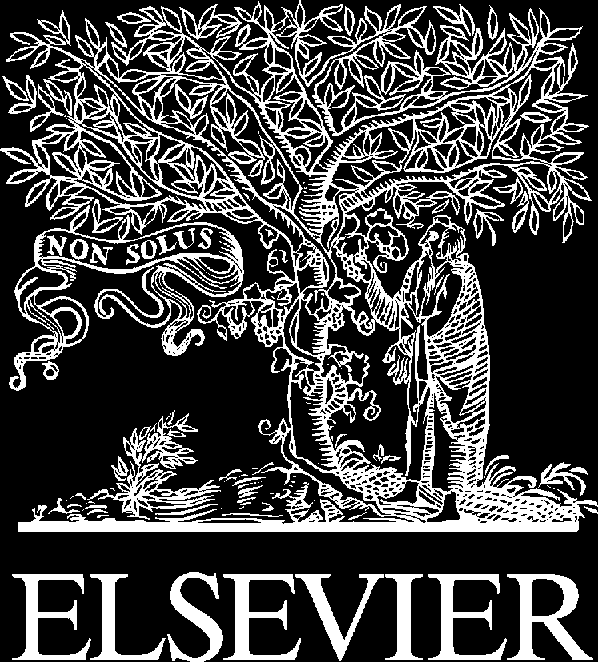

xref 7: 586x75 px; placements=[{'page': 4, 'bbox': [85.8, 102.8, 367.4, 138.9]}]


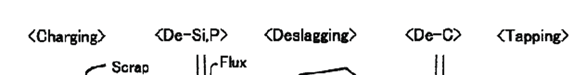

xref 8: 586x75 px; placements=[{'page': 4, 'bbox': [85.8, 138.7, 367.4, 174.8]}]


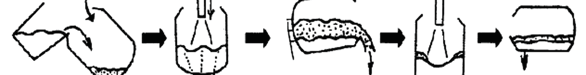

xref 9: 586x75 px; placements=[{'page': 4, 'bbox': [85.8, 174.6, 367.4, 210.5]}]


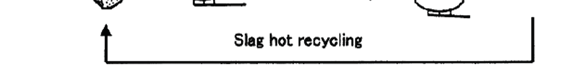

xref 10: 549x235 px; placements=[{'page': 4, 'bbox': [111.7, 252.1, 375.2, 365.1]}]


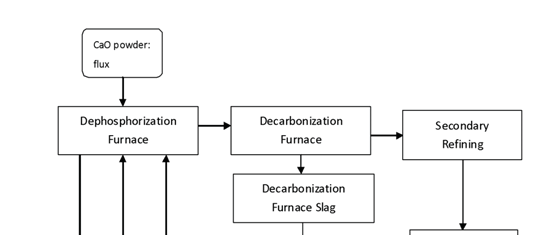

xref 11: 549x235 px; placements=[{'page': 4, 'bbox': [111.7, 364.9, 375.2, 477.9]}]


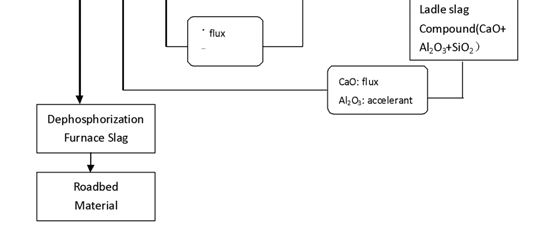

8 PDF image resource(s), not necessarily that many figures.


In [4]:
IMAGE_REVIEW_PDF = PDF_PATHS[0].name


for filename, result in results.items():
    print(f"\n{'=' * 70}\n{filename}: {result['page_count']} pages")
    print(
        f"Docling tables: {len(result['docling']['tables'])} | "
        f"PyMuPDF embedded image resources: {len(result['pymupdf']['embedded_images'])}"
    )
    markdown = result["docling"]["markdown"]
    display(
        Markdown(
            markdown[:1200]
            + ("\n\n… *preview; see parsed.json for full text*" if len(markdown) > 1200 else "")
        )
    )
    for number, table in enumerate(result["docling"]["tables"][:2], start=1):
        preview = table[:1200] + (
            "\n\n… *table preview; see parsed.json for full table*" if len(table) > 1200 else ""
        )
        display(Markdown(f"**Table {number}**\n\n{preview}"))
    if len(result["docling"]["tables"]) > 2:
        print(f"({len(result['docling']['tables']) - 2} more table(s) in parsed.json)")


def show_embedded_images(filename: str) -> None:
    """Display extracted image resources with their source-page placements."""
    image_dir = OUTPUT_DIR / Path(filename).stem / "images"
    records = results[filename]["pymupdf"]["embedded_images"]
    for record in records:
        print(
            f"xref {record['xref']}: {record['width']}x{record['height']} px; "
            f"placements={record['placements']}"
        )
        display(Image(data=(image_dir / record["path"]).read_bytes()))
    print(f"{len(records)} PDF image resource(s), not necessarily that many figures.")


def show_page(filename: str, page_number: int) -> None:
    """Render a source page with embedded-image bounding boxes outlined."""
    pdf_path = INPUT_DIR / filename
    if pdf_path not in PDF_PATHS:
        raise ValueError(f"Choose a PDF from {INPUT_DIR}: {filename}")
    with pymupdf.open(pdf_path) as pdf:
        if not 1 <= page_number <= pdf.page_count:
            raise ValueError(f"Page must be between 1 and {pdf.page_count}.")
        page = pdf[page_number - 1]
        for record in results[filename]["pymupdf"]["embedded_images"]:
            for placement in record["placements"]:
                if placement["page"] == page_number:
                    page.draw_rect(pymupdf.Rect(*placement["bbox"]), color=(1, 0, 0), width=1)
        display(Image(data=page.get_pixmap(dpi=110).tobytes("png")))


show_embedded_images(IMAGE_REVIEW_PDF)
# Example: show_page(IMAGE_REVIEW_PDF, 4)

## Manual review

For each reviewed PDF, count semantic diagrams in the source pages. Classify each displayed PyMuPDF resource as a complete figure, a figure fragment, or decoration (such as journal branding); multiple fragments can belong to one diagram. Compare one source table's numeric entries with its parsed Markdown table and record the result here. The JSON is the saved result; the original PDFs remain unchanged.

| PDF | Diagrams in source | PyMuPDF resources | Relevant figure resources | Branding/decorative resources | Numbers checked / present | Notes |
|---|---:|---:|---:|---:|---:|---|
|  |  |  |  |  |  |  |
